Chargement des librairies et modules nécessaires.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.model_selection import cross_validate, RandomizedSearchCV, GridSearchCV, learning_curve
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from pathlib import Path
import data_loader

np.random.seed(0) # reproducible results

/home/yayel4289/coursUnif/bab3/ML/projet/code/src/data


Obtention des données d'entraînement et de test avec notre module `data_loader`

In [3]:
data_dir = Path("data")
X_train, X_test, y_train = data_loader.get_train_test_dfs(data_dir)
X_train = X_train.drop(columns=["CantonName", "CommuneName", "Einheit"], errors="ignore")
X_test = X_test.drop(columns=["CantonName", "CommuneName", "Einheit"], errors="ignore")
y_train = y_train.values.squeeze()

Définition de la grille des hyperparamètres pour performer une `GridSearchCV` par après.  
- `n_estimator` est $B$, le nombre d'arbres construits.
- `learning_rate` est $\lambda$, le taux d'apprentissage.
- `max_depth` est la profondeur maximale d'un arbre.
- `min_child_weight` est le nombre minimal requis de données qu'une feuille doit avoir.
- `subsample` est le pourcentage de données prises dans les données d'entraînement.
- `colsample_bytree` est le pourcentage de prédicteurs pris en compte par un arbre.


`max_depth` et `min_child_weight` sont des hyperparamètres jouant avec la variable $d$ (nombre de divisions) présenté dans la théorie.

In [4]:
param_grid_boost = {
    'regressor__n_estimators' : list(range(300, 1000+1, 100)),
    'regressor__learning_rate' :  [0.1, 0.05, 0.01, 0.005],
    'regressor__max_depth' : list(range(1, 6)),
    'regressor__min_child_weight': [2, 5, 10],
    'regressor__subsample' : [0.5, 0.6, 0.7, 0.8],
    'regressor__colsample_bytree' : [0.6, 0.8]
}

Recherche des hyperparamètres optimaux pour le `GradientBoostingRegressor` à l'aide d'une `RandomizedSearchCV`.  
L'objectif ici est d'avoir la meilleur RMSE en cross-validation possible.

In [5]:
xgb = XGBRegressor(random_state=0)
model = Pipeline(steps=[('imputer', SimpleImputer(strategy='mean')), ('regressor', xgb)])
grid = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid_boost,
    cv=10,
    scoring='neg_root_mean_squared_error',
    n_iter=100,
    random_state=0,
    return_train_score=True,
    n_jobs=-1,  # Entire CPU taken, resulting in slower outer performance
)
grid.fit(X_train, y_train)
best_cv_rmse = -grid.cv_results_['mean_test_score'][grid.best_index_]
best_train_rmse = -grid.cv_results_['mean_train_score'][grid.best_index_]

print("Best CV RMSE :", best_cv_rmse)
print("Best train RMSE :", best_train_rmse)
print("Best params:\n", grid.best_params_)

Best CV RMSE : 5.821296398408563
Best train RMSE : 1.4608544483649066
Best params:
 {'regressor__subsample': 0.7, 'regressor__n_estimators': 300, 'regressor__min_child_weight': 5, 'regressor__max_depth': 5, 'regressor__learning_rate': 0.05, 'regressor__colsample_bytree': 0.6}


Construction d'un graphique permettant de visualiser à quel point le modèle overfit en fonction de la taille du dataset.

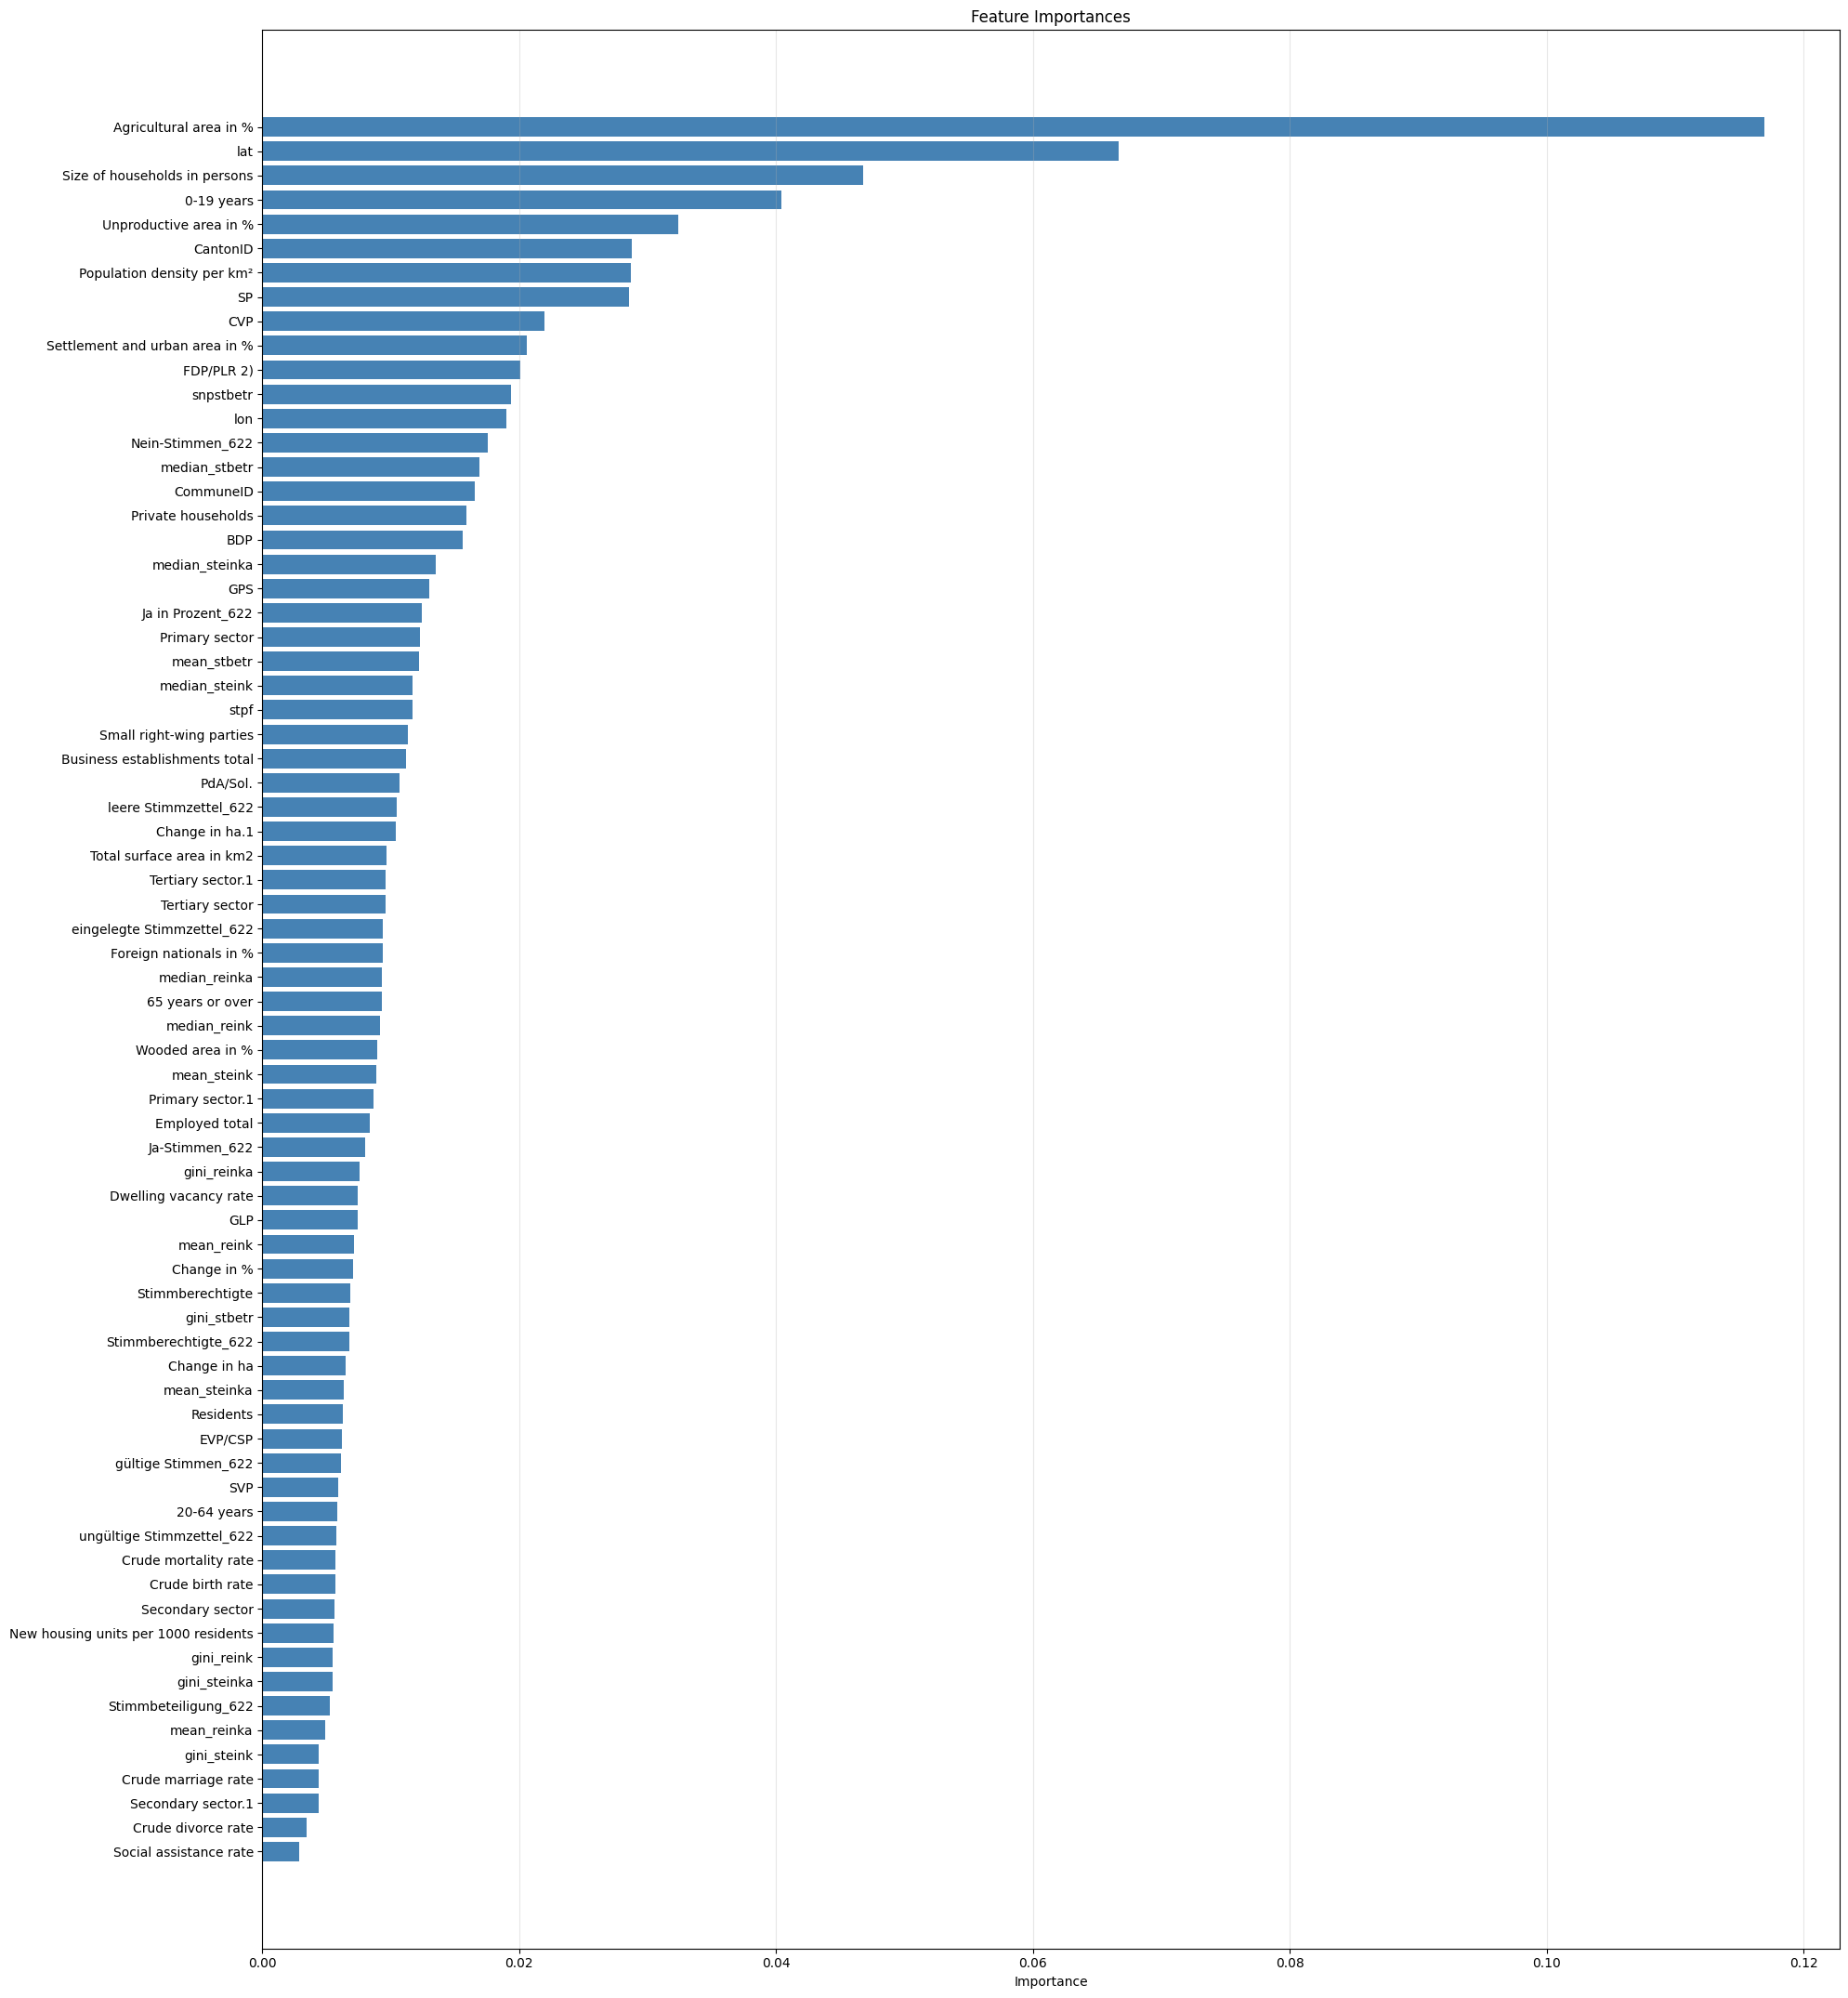

<Figure size 640x480 with 0 Axes>

In [8]:
gbr_fitted = grid.best_estimator_.named_steps['regressor']
importances = gbr_fitted.feature_importances_

fi_df = pd.DataFrame({'feature': X_train.columns, 'importance': importances})
fi_df = fi_df.sort_values('importance', ascending=False).reset_index(drop=True)
n = len(fi_df)

fig, ax = plt.subplots(figsize=(20, max(1, n * 0.3)))
bars = ax.barh(fi_df['feature'][::-1], fi_df['importance'][::-1], color='steelblue')
ax.set_xlabel('Importance')
ax.set_title('Feature Importances')
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()
plt.savefig("../boost_feature_importances.png")

Prédiction de `X_test` et production d'un ficher `csv` prêt à la soumission pour la compétition Kaggle.

In [7]:
y_predict = grid.predict(X_test)

submission_df = pd.DataFrame({
    'Id': X_test["CommuneID"],
    'Predicted': y_predict
})

submission_df.to_csv("../submission_boosting.csv", index=False)
print("Saved submission_boosting.csv for Kaggle")

display(submission_df.head())

Saved submission_boosting.csv for Kaggle


,Id,Predicted
0,69,47.813812
1,981,41.562035
2,5432,33.291443
3,387,47.142746
4,2194,35.124355
